In [6]:

!pip install -q huggingface_hub

from huggingface_hub import hf_hub_download

annotation_path = hf_hub_download(
    repo_id="iisc-aim/BMD-45",
    filename="BMD-45-Train/_annotations.coco.json",
    repo_type="dataset"
)

print("COCO annotation file downloaded successfully!")
print(annotation_path)


BMD-45-Train/_annotations.coco.json: reconstructing file:   0%|          |  0.00B / 49.4MB            

BMD-45-Train/_annotations.coco.json: downloading bytes:           |  0.00B            

COCO annotation file downloaded successfully!
/root/.cache/huggingface/hub/datasets--iisc-aim--BMD-45/snapshots/3e3f6a0b4834d282890c34986216c487914c5dff/BMD-45-Train/_annotations.coco.json


In [7]:

import json
from collections import Counter

# Load the COCO annotation file
with open(annotation_path, "r") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]
categories = coco["categories"]

print("========== COCO DATASET EXPLORATION ==========")
print("Total images:", len(images))
print("Total annotations:", len(annotations))
print("Total categories:", len(categories))

print("\n========== CATEGORY NAMES ==========")
for category in categories:
    print(category["id"], "-", category["name"])

print("\n========== FIRST IMAGE DETAILS ==========")
print(images[0])

print("\n========== FIRST ANNOTATION ==========")
print(annotations[0])


========== COCO DATASET EXPLORATION ==========
Total images: 35792
Total annotations: 373132
Total categories: 13

========== CATEGORY NAMES ==========
0 - Hatchback
1 - Sedan
2 - SUV
3 - MUV
4 - Bus
5 - Truck
6 - Three-wheeler
7 - Two-wheeler
8 - LCV
9 - Mini-bus
10 - Tempo-traveller
11 - Bicycle
12 - Van

========== FIRST IMAGE DETAILS ==========
{'file_name': 'images_000/41.png', 'height': 1080, 'id': 0, 'width': 1920}

========== FIRST ANNOTATION ==========
{'area': 59772, 'bbox': [1595.74, 447.21, 204, 293.00000000000006], 'category_id': 6, 'id': 1, 'image_id': 0, 'iscrowd': 0}


In [8]:

category_names = {
    category["id"]: category["name"]
    for category in categories
}

category_counts = Counter(
    category_names[ann["category_id"]]
    for ann in annotations
)

print("========== OBJECT CATEGORY COUNTS ==========")

for name, count in category_counts.most_common():
    print(f"{name}: {count}")


========== OBJECT CATEGORY COUNTS ==========
Two-wheeler: 171283
Three-wheeler: 65899
Hatchback: 35101
Sedan: 19970
LCV: 18115
SUV: 15573
Bus: 13899
Truck: 9968
MUV: 9092
Bicycle: 4713
Tempo-traveller: 4060
Van: 4020
Mini-bus: 1439


In [9]:

print("========== IMAGE FILE DETAILS ==========")

for img in images[:10]:
    print(img["file_name"])

print("\n========== IMAGE RECORD ==========")
print(images[0])


========== IMAGE FILE DETAILS ==========
images_000/41.png
images_000/47.png
images_000/71.png
images_000/94.png
images_000/170.png
images_000/183.png
images_000/187.png
images_000/224.png
images_000/247.png
images_000/320.png

========== IMAGE RECORD ==========
{'file_name': 'images_000/41.png', 'height': 1080, 'id': 0, 'width': 1920}


In [10]:

from huggingface_hub import hf_hub_download
import os
import shutil

image_dir = "/content/bmd45_images"
os.makedirs(image_dir, exist_ok=True)

# Download the first 3 images listed in the annotations
sample_images = images[:3]

for img in sample_images:
    filename = img["file_name"]

    try:
        image_path = hf_hub_download(
            repo_id="iisc-aim/BMD-45",
            repo_type="dataset",
            filename="BMD-45-Train/" + filename
        )

        destination = os.path.join(
            image_dir, os.path.basename(filename)
        )
        shutil.copy(image_path, destination)

        print("Downloaded:", filename, "->", destination)

    except Exception as e:
        print("Could not download:", filename)
        print(type(e).__name__, e)


BMD-45-Train/images_000/41.png: reconstructing file:   0%|          |  0.00B / 3.06MB            

BMD-45-Train/images_000/41.png: downloading bytes:           |  0.00B            

Downloaded: images_000/41.png -> /content/bmd45_images/41.png


BMD-45-Train/images_000/47.png: reconstructing file:   0%|          |  0.00B / 4.21MB            

BMD-45-Train/images_000/47.png: downloading bytes:           |  0.00B            

Downloaded: images_000/47.png -> /content/bmd45_images/47.png


BMD-45-Train/images_000/71.png: reconstructing file:   0%|          |  0.00B / 2.56MB            

BMD-45-Train/images_000/71.png: downloading bytes:           |  0.00B            

Downloaded: images_000/71.png -> /content/bmd45_images/71.png


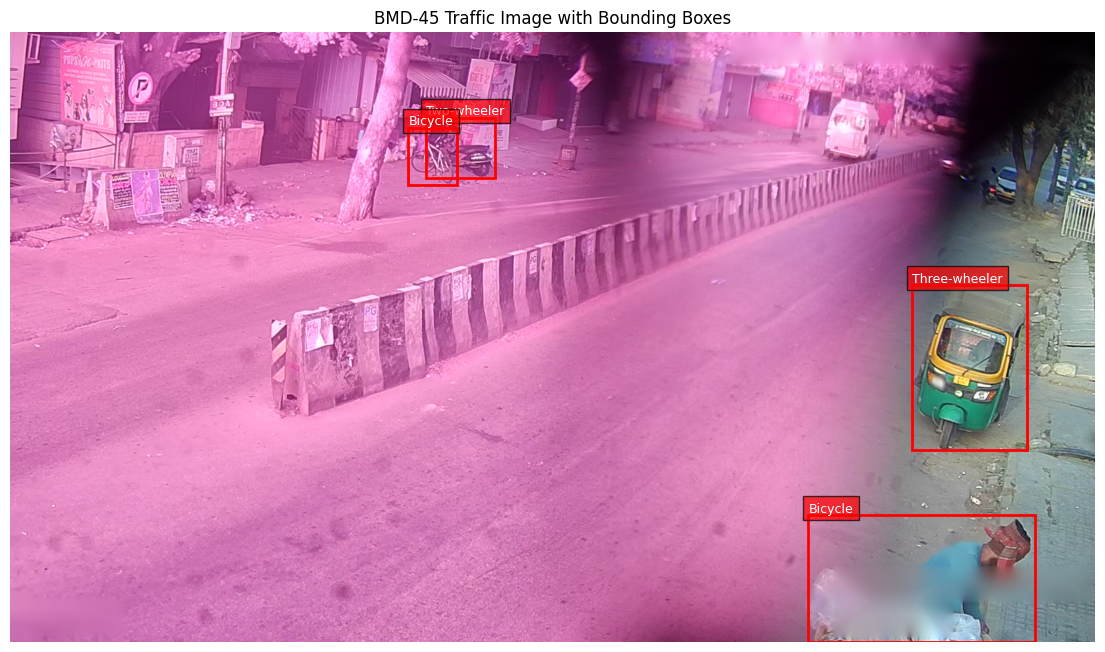

Image ID: 0
Number of annotations: 4


In [11]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import os

# Map category IDs to names
category_names = {
    cat["id"]: cat["name"] for cat in categories
}

# Display the first downloaded image
first_img = sample_images[0]

local_path = os.path.join(
    image_dir, os.path.basename(first_img["file_name"])
)

image = Image.open(local_path).convert("RGB")

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(image)

# Select annotations for this image
image_annotations = [
    ann for ann in annotations
    if ann["image_id"] == first_img["id"]
]

# Draw bounding boxes and labels
for ann in image_annotations:
    x, y, w, h = ann["bbox"]

    rect = patches.Rectangle(
        (x, y), w, h,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )
    ax.add_patch(rect)

    label = category_names[ann["category_id"]]
    ax.text(
        x, max(0, y - 5), label,
        color="white",
        fontsize=9,
        bbox=dict(facecolor="red", alpha=0.7)
    )

ax.set_title("BMD-45 Traffic Image with Bounding Boxes")
ax.axis("off")
plt.show()

print("Image ID:", first_img["id"])
print("Number of annotations:", len(image_annotations))


========== CATEGORY DISTRIBUTION ==========
Two-wheeler: 171283
Three-wheeler: 65899
Hatchback: 35101
Sedan: 19970
LCV: 18115
SUV: 15573
Bus: 13899
Truck: 9968
MUV: 9092
Bicycle: 4713
Tempo-traveller: 4060
Van: 4020
Mini-bus: 1439


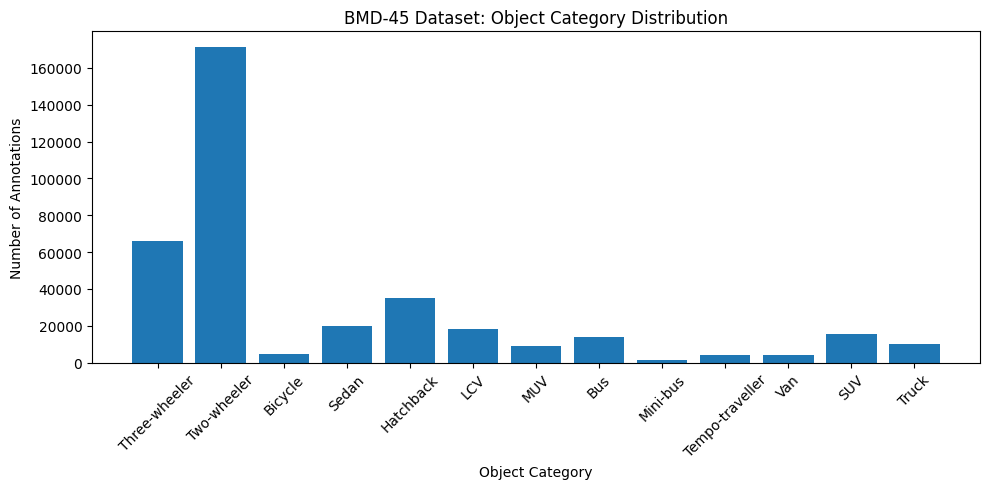

In [12]:

from collections import Counter
import matplotlib.pyplot as plt

category_names = {
    cat["id"]: cat["name"]
    for cat in categories
}

category_counts = Counter(
    category_names[ann["category_id"]]
    for ann in annotations
)

print("========== CATEGORY DISTRIBUTION ==========")

for name, count in category_counts.most_common():
    print(f"{name}: {count}")

plt.figure(figsize=(10, 5))
plt.bar(category_counts.keys(), category_counts.values())
plt.title("BMD-45 Dataset: Object Category Distribution")
plt.xlabel("Object Category")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


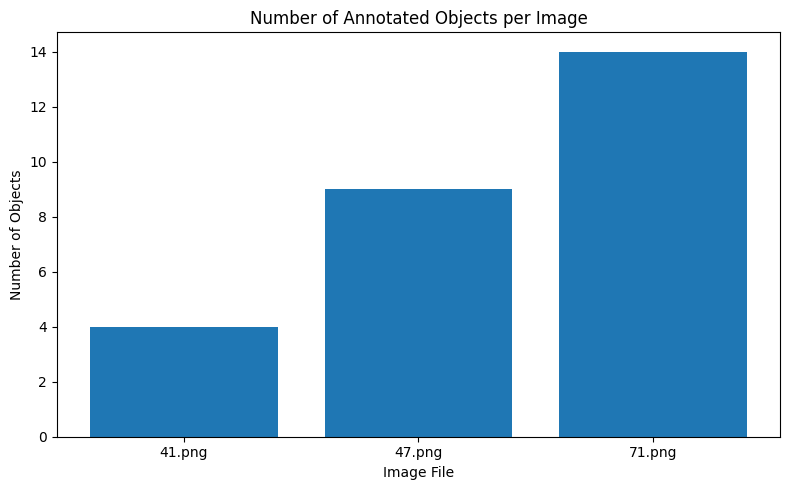

In [15]:

import matplotlib.pyplot as plt

image_object_counts = []

for img_info in sample_images:
    count = sum(
        1 for ann in annotations
        if ann["image_id"] == img_info["id"]
    )

    image_object_counts.append(count)

image_labels = [
    img["file_name"].split("/")[-1]
    for img in sample_images
]

plt.figure(figsize=(8, 5))
plt.bar(image_labels, image_object_counts)
plt.title("Number of Annotated Objects per Image")
plt.xlabel("Image File")
plt.ylabel("Number of Objects")
plt.tight_layout()
plt.show()


Bounding-box size counts:
Small: 4101
Medium: 124563
Large: 244468


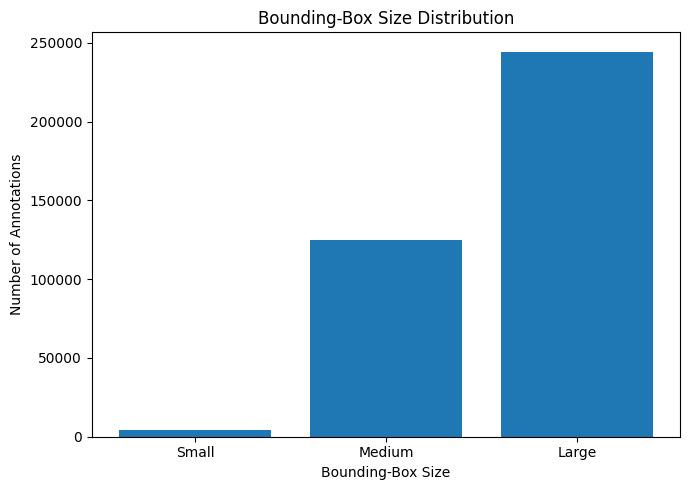

In [16]:

import matplotlib.pyplot as plt
from collections import Counter

box_sizes = Counter()

for ann in annotations:
    x, y, width, height = ann["bbox"]
    area = width * height

    if area < 32**2:
        box_sizes["Small"] += 1
    elif area < 96**2:
        box_sizes["Medium"] += 1
    else:
        box_sizes["Large"] += 1

size_order = ["Small", "Medium", "Large"]
size_counts = [box_sizes[size] for size in size_order]

print("Bounding-box size counts:")
for size, count in zip(size_order, size_counts):
    print(f"{size}: {count}")

plt.figure(figsize=(7, 5))
plt.bar(size_order, size_counts)
plt.title("Bounding-Box Size Distribution")
plt.xlabel("Bounding-Box Size")
plt.ylabel("Number of Annotations")
plt.tight_layout()
plt.show()


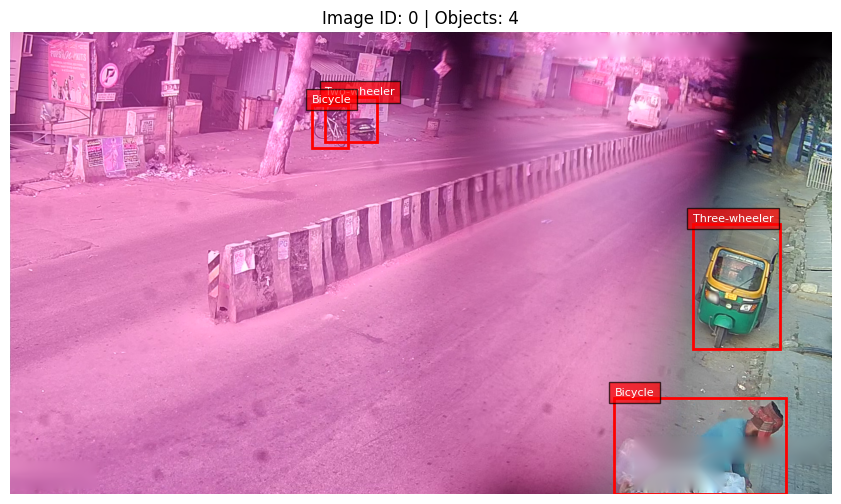

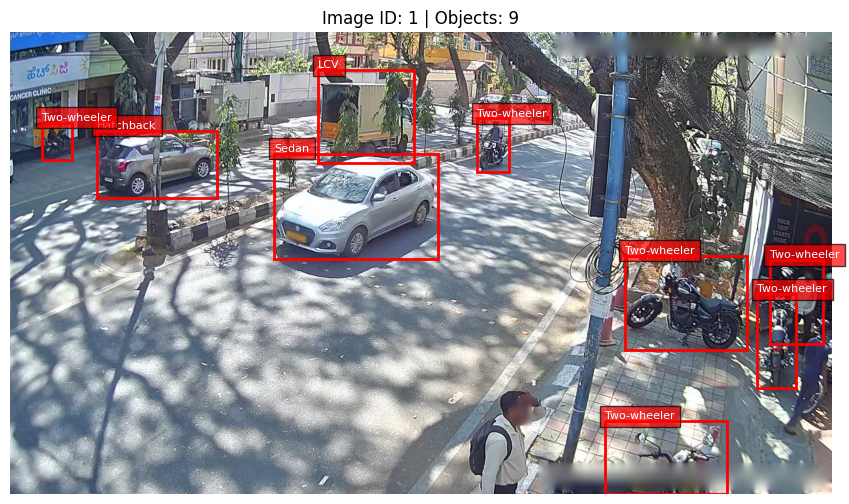

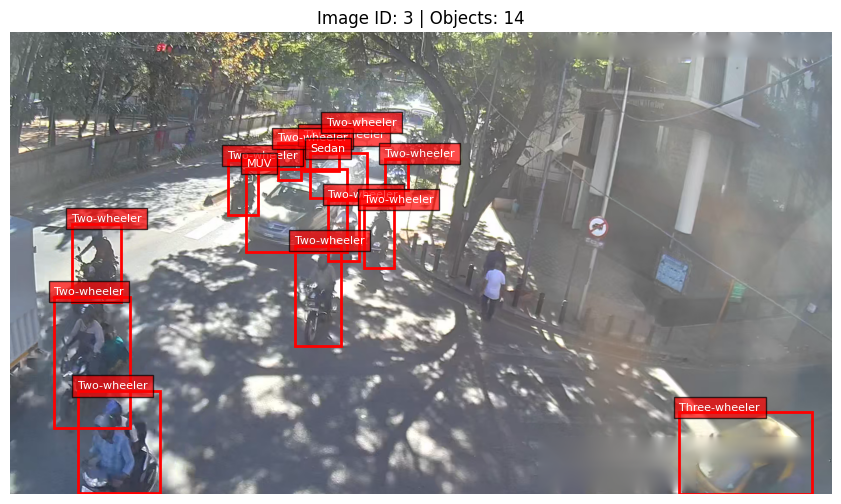

In [13]:

for img_info in sample_images:
    local_path = os.path.join(
        image_dir,
        os.path.basename(img_info["file_name"])
    )

    image = Image.open(local_path).convert("RGB")

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.imshow(image)

    anns = [
        ann for ann in annotations
        if ann["image_id"] == img_info["id"]
    ]

    for ann in anns:
        x, y, w, h = ann["bbox"]

        rect = patches.Rectangle(
            (x, y), w, h,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )
        ax.add_patch(rect)

        label = category_names[ann["category_id"]]
        ax.text(
            x, max(0, y - 5), label,
            color="white",
            fontsize=8,
            bbox=dict(facecolor="red", alpha=0.7)
        )

    ax.set_title(
        f"Image ID: {img_info['id']} | Objects: {len(anns)}"
    )
    ax.axis("off")
    plt.show()


In [14]:

print("========== BOUNDING-BOX COORDINATES ==========")

for ann in image_annotations:
    print(
        "Category:", category_names[ann["category_id"]],
        "| Bounding box [x, y, width, height]:",
        ann["bbox"]
    )


========== BOUNDING-BOX COORDINATES ==========
Category: Three-wheeler | Bounding box [x, y, width, height]: [1595.74, 447.21, 204, 293.00000000000006]
Category: Two-wheeler | Bounding box [x, y, width, height]: [736.03, 151.65, 122, 105.99999999999997]
Category: Bicycle | Bounding box [x, y, width, height]: [1412.38, 854.3, 401, 225]
Category: Bicycle | Bounding box [x, y, width, height]: [704.43, 169.07, 86, 102]
